# goodbooks-10k

This dataset contains six million ratings for ten thousand most popular (with most ratings) books.

https://github.com/zygmuntz/goodbooks-10k




## Objectives / Questions to answer

1. How well do KNNBasic and SVD predict users’ book ratings, and which model performs more consistently?

2. How effective are KNNBasic and SVD at generating relevant Top-N book recommendations?

3. What patterns or biases are evident in the recommendations produced by the two models?

# Libraries

In [ ]:
#Levenshtein Distance to calculate the differences between sequences.

!pip install python-levenshtein fuzzywuzzy scikit-surprise

#Surprise is an open-source Python library for building recommender systems with explicit rating data.
#install scikit surprise using terminal with code below

#conda install -c conda-forge scikit-surprise

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 84.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 79.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [python-levenshtein]


In [ ]:
# allows us to access dataframes
import pandas as pd

# specialized class for handling sparse matrices (compressed)
from scipy.sparse import csr_matrix

# Library for visualizing charts
import matplotlib.pylab as plt

# Fuzzy gives us access to functions that allow text scoring of similarities
from fuzzywuzzy import fuzz

# Gives us access to the unsupervised algorithm knn
from sklearn.neighbors import NearestNeighbors

# Surprise is an easy-to-use Python scikit for recommender systems.
from surprise import SVD #SVD algorithm
from surprise import KNNBasic # Knn algorithm
from surprise import Dataset # Utility for loading datasets
from surprise import Reader # Allows surprise to interpret the ratings
from surprise.model_selection import cross_validate, KFold # cross validation utility

# Exploration

In [ ]:
base_url = "https://raw.githubusercontent.com/zygmuntz/goodbooks-10k/master/"

books = pd.read_csv(base_url + "books.csv")
ratings = pd.read_csv(base_url + "ratings.csv")
tags = pd.read_csv(base_url + "tags.csv")
book_tags = pd.read_csv(base_url + "book_tags.csv")
to_read = pd.read_csv(base_url + "to_read.csv")



| Notebook requirement | goodbooks-10k column | Source file |
|---|---|---|
| User ID | `user_id` | ratings.csv |
| Item ID | `book_id` | ratings.csv, books.csv |
| Rating | `rating` (integers 1-5) | ratings.csv |
| Item info | `title`, `original_title`, `authors`, `original_publication_year`, `average_rating` | books.csv |

**Not used:** timestamps and genre labels are not in this dataset. Tags (`book_tags.csv` and `tags.csv`) are available if genre-like features are needed later.

In [ ]:
#  Notebook mapping

ratings = ratings[["user_id", "book_id", "rating"]]
books = books[["book_id", "title", "original_title", "authors",
               "original_publication_year", "average_rating"]]

print(ratings.dtypes)
print("rating range:", ratings["rating"].min(), "-", ratings["rating"].max())
print("duplicate user-book pairs:", ratings.duplicated(["user_id", "book_id"]).sum())
print("ratings with a book_id missing from books:",
      (~ratings["book_id"].isin(books["book_id"])).sum())
print("missing values in books:\n", books.isna().sum())

user_id    int64
book_id    int64
rating     int64
dtype: object
rating range: 1 - 5
duplicate user-book pairs: 0
ratings with a book_id missing from books: 0
missing values in books:
 book_id                        0
title                          0
original_title               585
authors                        0
original_publication_year     21
average_rating                 0
dtype: int64


In [ ]:
print(books.shape)
print(ratings.shape)

books.info()
books.head()

(10000, 6)
(5976479, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   book_id                    10000 non-null  int64  
 1   title                      10000 non-null  object 
 2   original_title             9415 non-null   object 
 3   authors                    10000 non-null  object 
 4   original_publication_year  9979 non-null   float64
 5   average_rating             10000 non-null  float64
dtypes: float64(2), int64(1), object(3)
memory usage: 468.9+ KB


,book_id,title,original_title,authors,original_publication_year,average_rating
0,1,"The Hunger Games (The Hunger Games, #1)",The Hunger Games,Suzanne Collins,2008.0,4.34
1,2,Harry Potter and the Sorcerer's Stone (Harry P...,Harry Potter and the Philosopher's Stone,"J.K. Rowling, Mary GrandPré",1997.0,4.44
2,3,"Twilight (Twilight, #1)",Twilight,Stephenie Meyer,2005.0,3.57
3,4,To Kill a Mockingbird,To Kill a Mockingbird,Harper Lee,1960.0,4.25
4,5,The Great Gatsby,The Great Gatsby,F. Scott Fitzgerald,1925.0,3.89


In [ ]:
ratings.info()
ratings.head()
ratings.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5976479 entries, 0 to 5976478
Data columns (total 3 columns):
 #   Column   Dtype
---  ------   -----
 0   user_id  int64
 1   book_id  int64
 2   rating   int64
dtypes: int64(3)
memory usage: 136.8 MB


,user_id,book_id,rating
count,5.976479e+06,5.976479e+06,5.976479e+06
mean,2.622446e+04,2.006477e+03,3.919866e+00
std,1.541323e+04,2.468499e+03,9.910868e-01
min,1.000000e+00,1.000000e+00,1.000000e+00
25%,1.281300e+04,1.980000e+02,3.000000e+00
50%,2.593800e+04,8.850000e+02,4.000000e+00
75%,3.950900e+04,2.973000e+03,5.000000e+00
max,5.342400e+04,1.000000e+04,5.000000e+00


## Quality Checks

In [ ]:
# 1. Dataset size
num_users = ratings["user_id"].nunique()
num_items = ratings["book_id"].nunique()
print("1. Dataset size")
print(f"Unique users in ratings:  {num_users:,}")
print(f"Unique books in ratings:  {num_items:,}")
print(f"Books in books table:     {len(books):,}")
print(f"Total ratings:            {len(ratings):,}\n")

# 2. Missing values
print("2. Missing values")
print("ratings:\n", ratings.isna().sum().to_string(), "\n")
print("books (columns with nulls only):\n", books.isna().sum()[books.isna().sum() > 0].to_string(), "\n")

# 3. Duplicates
dup_pairs  = ratings.duplicated(subset=["user_id", "book_id"]).sum()
dup_rows   = ratings.duplicated().sum()
dup_books  = books["book_id"].duplicated().sum()
print("3. Duplicates")
print(f"Duplicate user-book pairs:  {dup_pairs:,}")
print(f"Fully duplicated rows:      {dup_rows:,}")
print(f"Duplicate book_id in books: {dup_books:,}\n")

# 4. Invalid IDs
orphan_ratings = (~ratings["book_id"].isin(books["book_id"])).sum()
unrated_books  = (~books["book_id"].isin(ratings["book_id"])).sum()
bad_ids        = ((ratings["user_id"] <= 0) | (ratings["book_id"] <= 0)).sum()
print("4. Invalid IDs")
print(f"Ratings whose book_id is not in books:  {orphan_ratings:,}")
print(f"Books with no ratings:                  {unrated_books:,}")
print(f"Non-positive user_id or book_id:        {bad_ids:,}\n")

# 5. Unusual rating values
bad_ratings = (~ratings["rating"].between(1, 5)).sum()
print("5. Rating values")
print(ratings["rating"].value_counts().sort_index().to_string())
print(f"Ratings outside 1-5:  {bad_ratings:,}")
print(f"Rating dtype:         {ratings['rating'].dtype}\n")

# Summary (for the cleaning notes)
summary = pd.DataFrame({
    "check": ["Missing values in ratings", "Duplicate user-book pairs",
              "Ratings with book_id not in books", "Non-positive IDs",
              "Ratings outside 1-5", "Books with no ratings"],
    "count": [ratings.isna().sum().sum(), dup_pairs, orphan_ratings,
              bad_ids, bad_ratings, unrated_books],
})
display(summary)

1. Dataset size
Unique users in ratings:  53,424
Unique books in ratings:  10,000
Books in books table:     10,000
Total ratings:            5,976,479

2. Missing values
ratings:
 user_id    0
book_id    0
rating     0 

books (columns with nulls only):
 original_title               585
original_publication_year     21 

3. Duplicates
Duplicate user-book pairs:  0
Fully duplicated rows:      0
Duplicate book_id in books: 0

4. Invalid IDs
Ratings whose book_id is not in books:  0
Books with no ratings:                  0
Non-positive user_id or book_id:        0

5. Rating values
rating
1     124195
2     359257
3    1370916
4    2139018
5    1983093
Ratings outside 1-5:  0
Rating dtype:         int64



,check,count
0,Missing values in ratings,0
1,Duplicate user-book pairs,0
2,Ratings with book_id not in books,0
3,Non-positive IDs,0
4,Ratings outside 1-5,0
5,Books with no ratings,0


In [ ]:
#understand unique counts for the dataset

num_users = len(ratings.user_id.unique())
num_items = len(ratings.book_id.unique())
print('There are {} unique users and {} unique books in this data set'.format(num_users, num_items))

There are 53424 unique users and 10000 unique books in this data set


In [ ]:
def describe_subset(df, label):
    n_users = df["user_id"].nunique()
    n_books = df["book_id"].nunique()
    n_ratings = len(df)
    density = n_ratings / (n_users * n_books)
    return {"stage": label, "users": n_users, "books": n_books,
            "ratings": n_ratings, "density": density, "sparsity": 1 - density}

## EDA

Text(0.5, 1.0, 'Count of Book Ratings per User Id')

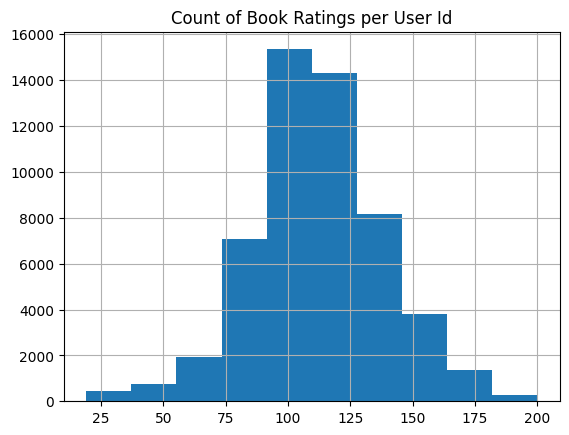

In [ ]:
#How many ratings per User ID do we have?

ratings[['user_id','book_id']].groupby(['user_id']).count().hist()
plt.title("Count of Book Ratings per User Id")


#most of the user have 15,000 number of ratings

In [ ]:
ratings[['user_id','book_id']].groupby(['user_id']).count().describe()

#there are 53,424 unique users
#what else can we say about the users?

,book_id
count,53424.000000
mean,111.868804
std,26.071224
min,19.000000
25%,96.000000
50%,111.000000
75%,128.000000
max,200.000000


In [ ]:
# Summary of ratings per user
ratings[['user_id','book_id']].groupby(['user_id']).count().describe()


,book_id
count,53424.000000
mean,111.868804
std,26.071224
min,19.000000
25%,96.000000
50%,111.000000
75%,128.000000
max,200.000000


The table above is the number of ratings per user. Every user has between 19 and 200 ratings (median 111, mean about 112)

In [ ]:
ratings[['user_id','book_id']].groupby(['book_id']).count().describe()

,user_id
count,10000.000000
mean,597.647900
std,1267.289788
min,8.000000
25%,155.000000
50%,248.000000
75%,503.000000
max,22806.000000


**Books:** popularity is highly imbalanced. The median book has 248 ratings, the mean is about 598 and the maximum is 22,806.

<Axes: title={'center': 'Count of Rating Score'}, xlabel='rating'>

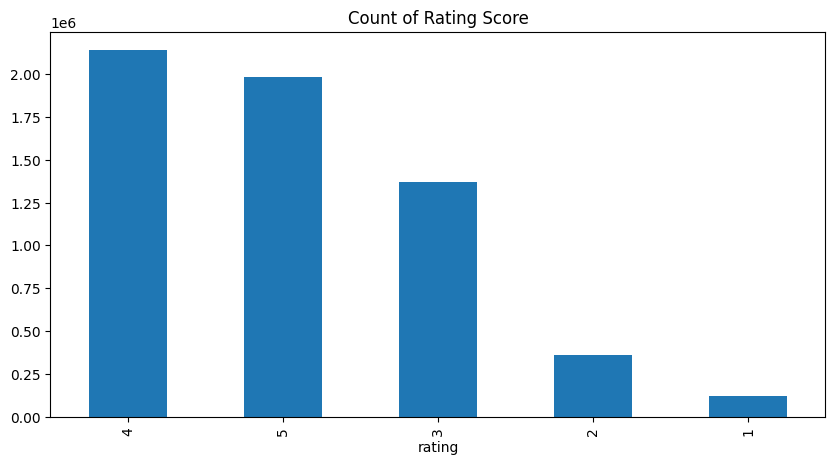

In [ ]:
#Ratings distribution

ratings['rating'].value_counts().plot.bar(title="Count of Rating Score",figsize=(10,5))

#what can we say about the ratings scores?

Ratings are strongly skewed toward positive scores, with 4- and 5-star ratings dominating, while 1- and 2-star ratings are relatively rare.

In [ ]:
# Sparsity
num_users = ratings["user_id"].nunique()
num_items = ratings["book_id"].nunique()
n_ratings = len(ratings)

possible = num_users * num_items
density = n_ratings / possible

print(f"Possible user-book pairs: {possible:,}")
print(f"Observed ratings:         {n_ratings:,}")
print(f"Density:  {density:.2%}")
print(f"Sparsity: {1 - density:.2%}")

Possible user-book pairs: 534,240,000
Observed ratings:         5,976,479
Density:  1.12%
Sparsity: 98.88%


About 98.9% of possible user-book pairs have no rating (density about 1.1%). The dataset is highly sparse: the average user has rated about 112 of 10,000 books. We will be using CSR matrix

In [ ]:
# based on this we can identify a threshold for amount of ratings to use per user/book
# ie. what is a popular book? an active user?
# Feel free to make this more or less restrictive as your model requires

# Preprocessing

In [ ]:
item_cnt = ratings.groupby("book_id").size()
for t in (300, 500, 1000, 2000, 3000, 5000, 7000):
    nb = (item_cnt >= t).sum()
    nr = item_cnt[item_cnt >= t].sum()
    print(f"threshold {t:>5}: {nb:>5} books | {nr:>9,} ratings")

threshold   300:  4164 books | 4,958,356 ratings
threshold   500:  2526 books | 4,329,108 ratings
threshold  1000:  1229 books | 3,427,913 ratings
threshold  2000:   537 books | 2,475,751 ratings
threshold  3000:   320 books | 1,948,597 ratings
threshold  5000:   153 books | 1,318,848 ratings
threshold  7000:    77 books |   869,688 ratings


In [ ]:
# Given some of our findings, let's try to optimize our dataset by filtering to only the data that we need

#why do we do this? #this is the minimum number of ratings per book

popularity_thres = 3000
book_rating_cnt_df = ratings[['rating','book_id']].groupby(['book_id']).count()
popular_books_df = book_rating_cnt_df[book_rating_cnt_df['rating']>=popularity_thres]


filtered_pop_books_df = ratings[ratings.book_id.isin(popular_books_df.index.values)]

print('shape of original ratings data: ', ratings.shape)
print('shape of ratings data after dropping unpopular books: ', filtered_pop_books_df.shape)

shape of original ratings data:  (5976479, 3)
shape of ratings data after dropping unpopular books:  (1948597, 3)


Ratings per user among the 320 kept books:
count    53288.0
mean        36.6
std         19.3
min          1.0
25%         22.0
50%         35.0
75%         49.0
max        148.0 



,users,cumulative users,cumulative % of all users
ratings per user,,,
1,216,216,0.41%
2,235,451,0.85%
3,291,742,1.39%
4,312,1054,1.98%
5,371,1425,2.67%
6,394,1819,3.41%
7,453,2272,4.26%
8,508,2780,5.22%
9,551,3331,6.25%


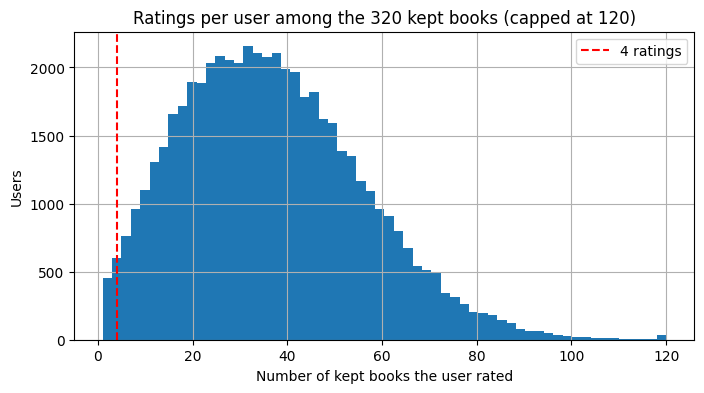

In [ ]:
# How many of the 320 (popularity_thres = 3000) kept books has each user rated?
user_cnt_kept = filtered_pop_books_df.groupby("user_id").size()
print("Ratings per user among the 320 kept books:")
print(user_cnt_kept.describe().round(1).to_string(), "\n")

# Users with very few ratings (1-10), with cumulative share
low = (user_cnt_kept.value_counts().reindex(range(1, 11), fill_value=0)
       .rename("users").rename_axis("ratings per user").to_frame())
low["cumulative users"] = low["users"].cumsum()
low["cumulative % of all users"] = low["cumulative users"] / len(user_cnt_kept)
display(low.style.format({"cumulative % of all users": "{:.2%}"}))

fig, ax = plt.subplots(figsize=(8, 4))
user_cnt_kept.clip(upper=120).hist(bins=60, ax=ax)
ax.axvline(4, color="red", ls="--", label="4 ratings")
ax.set(title="Ratings per user among the 320 kept books (capped at 120)",
       xlabel="Number of kept books the user rated", ylabel="Users")
ax.legend()
plt.show()

In [ ]:
# filtering for active users
ratings_thres = 4

kept_counts = filtered_pop_books_df.groupby("user_id").size()
active_ids = kept_counts[kept_counts >= ratings_thres].index

filtered_popular_active_df = filtered_pop_books_df[
    filtered_pop_books_df["user_id"].isin(active_ids)
].reset_index(drop=True)

display(pd.DataFrame([
    describe_subset(ratings, "Original"),
    describe_subset(filtered_pop_books_df, f"Books with ≥{popularity_thres} ratings"),
    describe_subset(filtered_popular_active_df, f"+ users with ≥{ratings_thres} kept ratings"),
]).set_index("stage").style.format({"users": "{:,}", "books": "{:,}", "ratings": "{:,}",
                                    "density": "{:.2%}", "sparsity": "{:.2%}"}))

,users,books,ratings,density,sparsity
stage,,,,,
Original,"53,424","10,000","5,976,479",1.12%,98.88%
Books with ≥3000 ratings,"53,288",320,"1,948,597",11.43%,88.57%
+ users with ≥4 kept ratings,"52,546",320,"1,947,038",11.58%,88.42%


In [ ]:
filtered_popular_active_df.head()

,user_id,book_id,rating
0,1,258,5
1,2,26,4
2,2,33,4
3,2,301,5
4,4,70,4


In [ ]:
# Let's transform this into a book-user pivot table
# Let's join them up first using a left join operation on book_id

filtered_book_ratings_merged_df = pd.merge(filtered_popular_active_df,books, how='left', on=['book_id'])
filtered_book_ratings_merged_df.head()

,user_id,book_id,rating,title,original_title,authors,original_publication_year,average_rating
0,1,258,5,The Shadow of the Wind (The Cemetery of Forgot...,La sombra del viento,"Carlos Ruiz Zafón, Lucia Graves",2001.0,4.24
1,2,26,4,"The Da Vinci Code (Robert Langdon, #2)",The Da Vinci Code,Dan Brown,2003.0,3.79
2,2,33,4,Memoirs of a Geisha,Memoirs of a Geisha,Arthur Golden,1997.0,4.08
3,2,301,5,Heart of Darkness,Heart of Darkness,Joseph Conrad,1899.0,3.42
4,4,70,4,"Ender's Game (Ender's Saga, #1)",Ender's Game,Orson Scott Card,1985.0,4.30


In [ ]:
# Now let's pivot the dataframe such that it will have book_id as the index, and user_id as columns
filtered_book_ratings_df = pd.pivot(filtered_book_ratings_merged_df,index='book_id', columns='user_id', values='rating').fillna(0)
filtered_book_ratings_df.head()


user_id,1,2,3,4,5,6,7,8,9,10,...,53414,53415,53417,53418,53419,53420,53421,53422,53423,53424
book_id,,,,,,,,,,,,,,,,,,,,,
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,...,3.0,0.0,4.0,5.0,4.0,4.0,4.0,4.0,4.0,4.0
2,0.0,5.0,0.0,5.0,0.0,0.0,0.0,0.0,4.0,0.0,...,4.0,0.0,0.0,0.0,5.0,5.0,5.0,5.0,5.0,5.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,0.0,...,2.0,0.0,0.0,0.0,3.0,3.0,0.0,0.0,0.0,4.0
4,5.0,0.0,3.0,4.0,0.0,0.0,0.0,3.0,0.0,5.0,...,0.0,0.0,0.0,0.0,3.0,0.0,5.0,0.0,5.0,5.0
5,0.0,5.0,0.0,4.0,0.0,0.0,3.0,3.0,5.0,5.0,...,0.0,0.0,0.0,0.0,3.0,2.0,4.0,0.0,0.0,0.0


In [ ]:
#Matrices that contain mostly zero values are called sparse,
#distinct from matrices where most of the values are non-zero, called dense.

#It is computationally expensive to represent and work with sparse matrices as though they are dense,
#and much improvement in performance can be achieved by using representations and operations
#that specifically handle the matrix sparsity.

#Instead of storing zeroes with non-zero elements, we only store non-zero elements.
#This means storing non-zero elements with triples- (Row, Column, value).

# Now given that this is a sparse matrix, we will use scipy which has a matrix class
# that is optimized to handle sparse matrix objects

#The function csr_matrix() is used to create a sparse matrix of compressed sparse row format
#whereas csc_matrix() is used to create a sparse matrix of compressed sparse column format.


book_ratings_mat = csr_matrix(filtered_book_ratings_df.values)

# Verify dimensions, labels and contents
n_books, n_users = filtered_book_ratings_df.shape
print("Pivot shape (books x users):", filtered_book_ratings_df.shape)
print("CSR shape:                  ", book_ratings_mat.shape)
assert book_ratings_mat.shape == filtered_book_ratings_df.shape
assert book_ratings_mat.nnz == len(filtered_popular_active_df), "nonzero count != number of ratings"

print(f"Stored ratings: {book_ratings_mat.nnz:,} | density: {book_ratings_mat.nnz / (n_books * n_users):.2%}")
print("Rating values in matrix:", sorted(set(book_ratings_mat.data)))   # expect only 1-5
print("Rows with no ratings:   ", (book_ratings_mat.getnnz(axis=1) == 0).sum())
print("Columns with no ratings:", (book_ratings_mat.getnnz(axis=0) == 0).sum())

# Spot check: a known rating must match the matrix
r = filtered_popular_active_df.iloc[0]
row = filtered_book_ratings_df.index.get_loc(r["book_id"])
col = filtered_book_ratings_df.columns.get_loc(r["user_id"])
print("Spot check:", r["rating"], "==", book_ratings_mat[row, col])

# this will be used as input to the model

Pivot shape (books x users): (320, 52546)
CSR shape:                   (320, 52546)
Stored ratings: 1,947,038 | density: 11.58%
Rating values in matrix: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
Rows with no ratings:    0
Columns with no ratings: 0
Spot check: 5 == 5.0


# Memory-based Approach
## Using KNN to estimate distance

Here we use item-based nearest neighbours: each book is represented by its vector of user ratings, and books are compared using cosine distance. For a given book, the model returns the k books with the most similar rating patterns as recommendations. This is separate from Surprise’s KNNBasic used later, which predicts ratings from similar books.

In [ ]:
# Metric is the distance algorithm to be used. You can find more choices here:
# https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.DistanceMetric.html#sklearn.neighbors.DistanceMetric

# algorithm is the type of tree search used by the model
# neighbors it the amount of neighbors identified
model_knn = NearestNeighbors(metric='cosine', algorithm='brute', n_neighbors=20, n_jobs=-1)

# fit
model_knn.fit(book_ratings_mat)


NearestNeighbors(algorithm='brute', metric='cosine', n_jobs=-1, n_neighbors=20)

KNN does not make any assumptions on the underlying data distribution but it relies on item feature similarity. When KNN makes inference about a movie, KNN will calculate the “distance” between the target movie and every other movie in its database, then it ranks its distances and returns the top K nearest neighbor movies as the most similar movie recommendations.

![alt text](https://miro.medium.com/max/975/1*OyYyr9qY-w8RkaRh2TKo0w.png)

In [ ]:
# Let's try it out
fav_book = "Twilight"
print('You have input book:', fav_book)

# find books that "match" title (NaN titles count as no match)
book_matches_df = filtered_book_ratings_merged_df[
    filtered_book_ratings_merged_df['original_title'].str.contains(fav_book, case=False, na=False)
]
book_matches_df = book_matches_df[['book_id', 'original_title']].drop_duplicates()
book_matches_df

You have input book: Twilight


,book_id,original_title
4213,3,Twilight
10709,49,"New Moon (Twilight, #2)"


# Let's Recommend!

In [ ]:
def recommend(query, n=10):
    """Item-based recommendations: the n books closest to the matched book in the item-user matrix."""
    pivot_ids = filtered_book_ratings_df.index
    names = books["original_title"].fillna(books["title"])      # built here, no extra column needed
    mask = (names.str.contains(query, case=False, na=False, regex=False)
            & books["book_id"].isin(pivot_ids))
    matches = books[mask]
    if matches.empty:
        print(f"No matching books for '{query}' in the filtered catalog")
        return None
    print("Matches:", matches["title"].tolist())
    book_id = matches.iloc[0]["book_id"]
    print("Using:  ", matches.iloc[0]["title"])

    row = pivot_ids.get_loc(book_id)          # row position in the matrix, not a DataFrame index
    dist, idx = model_knn.kneighbors(book_ratings_mat[row], n_neighbors=n + 1)
    rec_ids = pivot_ids[idx.ravel()]
    out = (books.set_index("book_id").loc[rec_ids, ["title"]]
           .assign(distance=dist.ravel()).reset_index())
    return out[out["book_id"] != book_id].head(n)

recommend("Twilight")

Matches: ['Twilight (Twilight, #1)', 'New Moon (Twilight, #2)']
Using:   Twilight (Twilight, #1)


,book_id,title,distance
1,49,"New Moon (Twilight, #2)",0.345761
2,52,"Eclipse (Twilight, #3)",0.348475
3,56,"Breaking Dawn (Twilight, #4)",0.374095
4,1,"The Hunger Games (The Hunger Games, #1)",0.437795
5,2,Harry Potter and the Sorcerer's Stone (Harry P...,0.475343
6,73,"The Host (The Host, #1)",0.556709
7,17,"Catching Fire (The Hunger Games, #2)",0.578414
8,20,"Mockingjay (The Hunger Games, #3)",0.595041
9,12,"Divergent (Divergent, #1)",0.600410
10,21,Harry Potter and the Order of the Phoenix (Har...,0.609180


In [ ]:
for q in ["Hunger Games", "Harry Potter", "Great Gatsby"]:
    print("=" * 60)
    display(recommend(q, n=10))

Matches: ['The Hunger Games (The Hunger Games, #1)']
Using:   The Hunger Games (The Hunger Games, #1)


,book_id,title,distance
1,17,"Catching Fire (The Hunger Games, #2)",0.276713
2,20,"Mockingjay (The Hunger Games, #3)",0.312425
3,2,Harry Potter and the Sorcerer's Stone (Harry P...,0.409895
4,3,"Twilight (Twilight, #1)",0.437795
5,12,"Divergent (Divergent, #1)",0.475861
6,31,The Help,0.540683
7,16,"The Girl with the Dragon Tattoo (Millennium, #1)",0.541141
8,21,Harry Potter and the Order of the Phoenix (Har...,0.549714
9,4,To Kill a Mockingbird,0.551099
10,25,Harry Potter and the Deathly Hallows (Harry Po...,0.551445


Matches: ["Harry Potter and the Sorcerer's Stone (Harry Potter, #1)", 'Harry Potter and the Prisoner of Azkaban (Harry Potter, #3)', 'Harry Potter and the Order of the Phoenix (Harry Potter, #5)', 'Harry Potter and the Chamber of Secrets (Harry Potter, #2)', 'Harry Potter and the Goblet of Fire (Harry Potter, #4)', 'Harry Potter and the Deathly Hallows (Harry Potter, #7)', 'Harry Potter and the Half-Blood Prince (Harry Potter, #6)', 'Harry Potter and the Cursed Child - Parts One and Two (Harry Potter, #8)']
Using:   Harry Potter and the Sorcerer's Stone (Harry Potter, #1)


,book_id,title,distance
1,18,Harry Potter and the Prisoner of Azkaban (Harr...,0.319496
2,23,Harry Potter and the Chamber of Secrets (Harry...,0.327067
3,24,Harry Potter and the Goblet of Fire (Harry Pot...,0.330699
4,21,Harry Potter and the Order of the Phoenix (Har...,0.342399
5,27,Harry Potter and the Half-Blood Prince (Harry ...,0.347832
6,25,Harry Potter and the Deathly Hallows (Harry Po...,0.348969
7,1,"The Hunger Games (The Hunger Games, #1)",0.409895
8,7,The Hobbit,0.474397
9,3,"Twilight (Twilight, #1)",0.475343
10,19,The Fellowship of the Ring (The Lord of the Ri...,0.506615


Matches: ['The Great Gatsby']
Using:   The Great Gatsby


,book_id,title,distance
1,4,To Kill a Mockingbird,0.412292
2,8,The Catcher in the Rye,0.422465
3,14,Animal Farm,0.506691
4,13,1984,0.510533
5,28,Lord of the Flies,0.513695
6,32,Of Mice and Men,0.520556
7,10,Pride and Prejudice,0.533790
8,29,Romeo and Juliet,0.550409
9,2,Harry Potter and the Sorcerer's Stone (Harry P...,0.558100
10,43,Jane Eyre,0.579440


In [ ]:
# Let's use surprise library to get a measure of our knn model's RMSE metric
# The Reader class is used to parse a file containing ratings.
# A reader is still needed but only the rating_scale param is required.

reader = Reader(rating_scale=(1, 5))

# The columns must correspond to user id, item id and ratings (in that order).
data = Dataset.load_from_df(filtered_book_ratings_merged_df[['user_id', 'book_id', 'rating']], reader)

# Same 5 folds for both models
kf = KFold(
    n_splits=5,
    random_state=42, # controls how ratings are divided into the five folds
    shuffle=True
)

# We'll train a knn model in surprise using our same data set
# knnbasic = KNNBasic() # replaced this because our colab does not have enough RAM
knnbasic = KNNBasic(sim_options={"user_based": False}, verbose=False)

# Run 5-fold cross-validation and print results.
knn_results = cross_validate(knnbasic, data, measures=['RMSE'], cv=kf, verbose=True)
knn_results


# Smaller RMSE means our model is able to give better recommendation
# Lower RMSE means more accurate rating predictions, not necessarily better Top-N recommendations.

#how do we try other knn models?

Evaluating RMSE of algorithm KNNBasic on 5 split(s).

                  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean    Std     
RMSE (testset)    0.9182  0.9174  0.9171  0.9186  0.9200  0.9183  0.0010  
Fit time          1.17    1.86    1.96    2.02    2.09    1.82    0.33    
Test time         21.58   21.86   21.17   21.72   21.56   21.58   0.23    


{'test_rmse': array([0.91823754, 0.91744856, 0.91706817, 0.91857618, 0.91999911]),
 'fit_time': (1.172865867614746,
  1.8639335632324219,
  1.964128017425537,
  2.015662908554077,
  2.093726396560669),
 'test_time': (21.578909873962402,
  21.860475540161133,
  21.172061681747437,
  21.715977907180786,
  21.560147762298584)}

# Model based approach

To Make things much more easier, we will be using the Surprise scikit which specializes in recommender models.

Continuing our Collaborative Filtering example, we will now use a model based approach via SVD (Singular Value Decomposition), as popularized by Simon Funk during the Netflix Prize. When baselines are not used, this is equivalent to Probabilistic Matrix Factorization [salakhutdinov2008a].

Supplementary reading for SVD: https://towardsdatascience.com/understanding-singular-value-decomposition-and-its-application-in-data-science-388a54be95d

SVD vs PCA https://jonathan-hui.medium.com/machine-learning-singular-value-decomposition-svd-principal-component-analysis-pca-1d45e885e491

"From a simplified perspective, PCA transforms data linearly into new properties that are not correlated with each other. For ML, positioning PCA as feature extraction may allow us to explore its potential better than dimension reduction.
What is the difference between SVD and PCA? SVD gives you the whole nine-yard of diagonalizing a matrix into special matrices that are easy to manipulate and to analyze. It lay down the foundation to untangle data into independent components. PCA skips less significant components. Obviously, we can use SVD to find PCA by truncating the less important basis vectors in the original SVD matrix"

In [ ]:
reader = Reader(rating_scale=(1, 5))

# The columns must correspond to user id, item id and ratings (in that order).
data = Dataset.load_from_df(filtered_book_ratings_merged_df[['user_id', 'book_id', 'rating']], reader)

# Set seed for SVD because SVD itself has random initialization
algo = SVD(random_state=42)

# Run 5-fold cross-validation and print results.
svd_results = cross_validate(algo, data, measures=['RMSE'], cv=kf, verbose=True)
svd_results

Evaluating RMSE of algorithm SVD on 5 split(s).

                  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean    Std     
RMSE (testset)    0.8631  0.8631  0.8612  0.8642  0.8650  0.8633  0.0013  
Fit time          20.27   20.51   21.48   20.83   21.23   20.86   0.45    
Test time         4.92    4.06    4.26    4.63    4.82    4.54    0.33    


{'test_rmse': array([0.8631399 , 0.86312874, 0.86122598, 0.86415505, 0.86501087]),
 'fit_time': (20.265864610671997,
  20.507437467575073,
  21.475006103515625,
  20.832639694213867,
  21.23265838623047),
 'test_time': (4.920768737792969,
  4.060166597366333,
  4.262641906738281,
  4.6256303787231445,
  4.82068133354187)}

# Let's try to predict

In [ ]:
algo.fit(data.build_full_trainset())

# Take a real (user, book) pair from the data; IDs must be ints, matching the DataFrame
row = filtered_popular_active_df.iloc[0]
uid, iid, true_rating = int(row["user_id"]), int(row["book_id"]), row["rating"]
print(f"Book: {books.loc[books['book_id'] == iid, 'title'].values[0]}")

print("Prediction for rating: ")
pred = algo.predict(uid, iid, r_ui=true_rating, verbose=True)
pred

Book: The Shadow of the Wind (The Cemetery of Forgotten Books,  #1)
Prediction for rating: 
user: 1          item: 258        r_ui = 5.00   est = 3.89   {'was_impossible': False}


Prediction(uid=1, iid=258, r_ui=np.int64(5), est=np.float64(3.8922837053034534), details={'was_impossible': False})

In [ ]:
# Our model was able to predict that the user (1) will rate the movie (3) a score of 4.17 (5)

# Let's compare the two using RMSE

In [ ]:
metric_df = pd.DataFrame()
metric_df['knn'] = knn_results['test_rmse']
metric_df['svd'] = svd_results['test_rmse']

tmp_dict1 = {'knn': metric_df['knn'].mean(), 'svd': metric_df['svd'].mean()}
tmp_dict2 = {'knn': metric_df['knn'].std(), 'svd': metric_df['svd'].std()}

# Create a DataFrame for the new rows
rows_df = pd.DataFrame([tmp_dict1, tmp_dict2])

# Concatenate instead of appending
metric_df = pd.concat([metric_df, rows_df], ignore_index=True)
metric_df.index = ['Fold 1', 'Fold 2', 'Fold 3', 'Fold 4', 'Fold 5', 'Mean', 'Std']
metric_df

,knn,svd
Fold 1,0.918238,0.863140
Fold 2,0.917449,0.863129
Fold 3,0.917068,0.861226
Fold 4,0.918576,0.864155
Fold 5,0.919999,0.865011
Mean,0.918266,0.863332
Std,0.001141,0.001415


# Hyperparameter tuning

Both models are tuned with 3-fold cross-validation on a random sample of 5,000 users, to keep the search fast. The best settings are then re-evaluated with 5-fold cross-validation on the remaining 47,546 users, who were not used for tuning. Hit Rate@10 is computed on a separate random sample of 5,000 of those users.

- **KNNBasic:** item-based. A user-based model on ~52k users needs a ~52k × 52k similarity matrix, which does not fit in Colab memory. Grid search over the number of neighbours (`k`), minimum neighbours (`min_k`) and similarity measure (36 combinations).
- **SVD:** grid search over latent factors (`n_factors`), training epochs (`n_epochs`), learning rate (`lr_all`) and regularization (`reg_all`) (108 combinations). All searches use fixed folds and seeds, so results are reproducible.

In [ ]:
import numpy as np
from surprise import Reader, Dataset, KNNBasic, SVD
from surprise.model_selection import GridSearchCV, RandomizedSearchCV, cross_validate, KFold

TUNE_USERS = 5000
rng = np.random.default_rng(42)

all_users = filtered_popular_active_df["user_id"].unique()
tune_users = rng.choice(all_users, size=min(TUNE_USERS, len(all_users)), replace=False)
tune_df = filtered_popular_active_df[filtered_popular_active_df["user_id"].isin(tune_users)]

display(pd.DataFrame([describe_subset(filtered_popular_active_df, "Full filtered data"),
                      describe_subset(tune_df, "Tuning sample")]).set_index("stage"))

reader = Reader(rating_scale=(1, 5))
tune_data = Dataset.load_from_df(tune_df[["user_id", "book_id", "rating"]], reader)

,users,books,ratings,density,sparsity
stage,,,,,
Full filtered data,52546,320,1947038,0.115794,0.884206
Tuning sample,5000,320,187264,0.117040,0.882960


In [ ]:
# Users never used for tuning: for the final RMSE check and for hit rate
eval_users = np.setdiff1d(all_users, tune_users)
eval_df = filtered_popular_active_df[filtered_popular_active_df["user_id"].isin(eval_users)]
eval_data = Dataset.load_from_df(eval_df[["user_id", "book_id", "rating"]], reader)

hr_users = rng.choice(eval_users, size=5000, replace=False)
hr_df = eval_df[eval_df["user_id"].isin(hr_users)]
hr_data = Dataset.load_from_df(hr_df[["user_id", "book_id", "rating"]], reader)
print(f"Eval users: {len(eval_users):,} | hit-rate users: {len(hr_users):,}")


Eval users: 47,546 | hit-rate users: 5,000


In [ ]:
knn_param_grid = {
    "k": [10, 20, 40, 60],
    "min_k": [1, 3, 5],
    "sim_options": {
        "name": ["msd", "cosine", "pearson"],
        "user_based": [False],          # item-based: 320 x 320 similarity matrix
    },
    "verbose": [False],
}

knn_gs = GridSearchCV(KNNBasic, knn_param_grid, measures=["rmse", "mae"],
                      #cv=3,
                      cv=KFold(n_splits=3, random_state=42, shuffle=True),
                      n_jobs=-1, joblib_verbose=1)
knn_gs.fit(tune_data)

knn_res = pd.DataFrame(knn_gs.cv_results)
knn_res["similarity"] = knn_res["param_sim_options"].apply(lambda d: d["name"])
knn_cols = ["param_k", "param_min_k", "similarity",
            "mean_test_rmse", "std_test_rmse", "mean_test_mae", "rank_test_rmse"]
display(knn_res[knn_cols].sort_values("rank_test_rmse").head(10))

best_knn_params = knn_gs.best_params["rmse"]
print("Best KNNBasic params:", best_knn_params)
print(f"Best CV RMSE (sample): {knn_gs.best_score['rmse']:.4f}")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  1.6min
[Parallel(n_jobs=-1)]: Done 108 out of 108 | elapsed:  3.7min finished


,param_k,param_min_k,similarity,mean_test_rmse,std_test_rmse,mean_test_mae,rank_test_rmse
3,10,3,msd,0.909911,0.002968,0.700390,1
0,10,1,msd,0.910014,0.002894,0.700350,2
6,10,5,msd,0.910135,0.002973,0.700826,3
12,20,3,msd,0.916627,0.002702,0.712173,4
9,20,1,msd,0.916729,0.002607,0.712134,5
15,20,5,msd,0.916850,0.002674,0.712610,6
14,20,3,pearson,0.918305,0.001760,0.716197,7
17,20,5,pearson,0.918366,0.001498,0.716600,8
11,20,1,pearson,0.918552,0.001541,0.716146,9
23,40,3,pearson,0.919958,0.001979,0.718256,10


Best KNNBasic params: {'k': 10, 'min_k': 3, 'sim_options': {'name': 'msd', 'user_based': False}, 'verbose': False}
Best CV RMSE (sample): 0.9099


In [ ]:
# Full grid search: tests all 108 combinations, so the result is the same on every run
svd_param_grid = {
    "n_factors": [20, 50, 100, 150],
    "n_epochs": [20, 30, 40],
    "lr_all": [0.002, 0.005, 0.01],
    "reg_all": [0.02, 0.05, 0.1],
    "random_state": [42],        # fixes SVD's random starting values
}

svd_gs = GridSearchCV(SVD, svd_param_grid, measures=["rmse", "mae"],
                      cv=KFold(n_splits=3, random_state=42, shuffle=True),
                      n_jobs=-1, joblib_verbose=1)
svd_gs.fit(tune_data)

svd_res = pd.DataFrame(svd_gs.cv_results)
svd_cols = ["param_n_factors", "param_n_epochs", "param_lr_all", "param_reg_all",
            "mean_test_rmse", "std_test_rmse", "mean_test_mae", "rank_test_rmse"]
display(svd_res[svd_cols].sort_values("rank_test_rmse").head(10))

best_svd_params = svd_gs.best_params["rmse"]
print("Best SVD params:", best_svd_params)
print(f"Best CV RMSE (sample): {svd_gs.best_score['rmse']:.4f}")

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:   46.1s
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed:  4.1min
[Parallel(n_jobs=-1)]: Done 324 out of 324 | elapsed:  8.4min finished


,param_n_factors,param_n_epochs,param_lr_all,param_reg_all,mean_test_rmse,std_test_rmse,mean_test_mae,rank_test_rmse
107,150,40,0.01,0.10,0.864256,0.002411,0.676502,1
80,100,40,0.01,0.10,0.864729,0.002495,0.676658,2
53,50,40,0.01,0.10,0.866672,0.002520,0.678385,3
98,150,30,0.01,0.10,0.869997,0.002223,0.682237,4
106,150,40,0.01,0.05,0.870321,0.002326,0.676360,5
71,100,30,0.01,0.10,0.870859,0.002386,0.682774,6
97,150,30,0.01,0.05,0.871773,0.002338,0.678449,7
26,20,40,0.01,0.10,0.871882,0.002013,0.682547,8
70,100,30,0.01,0.05,0.873515,0.002373,0.678547,9
79,100,40,0.01,0.05,0.873553,0.002439,0.677332,10


Best SVD params: {'n_factors': 150, 'n_epochs': 40, 'lr_all': 0.01, 'reg_all': 0.1, 'random_state': 42}
Best CV RMSE (sample): 0.8643


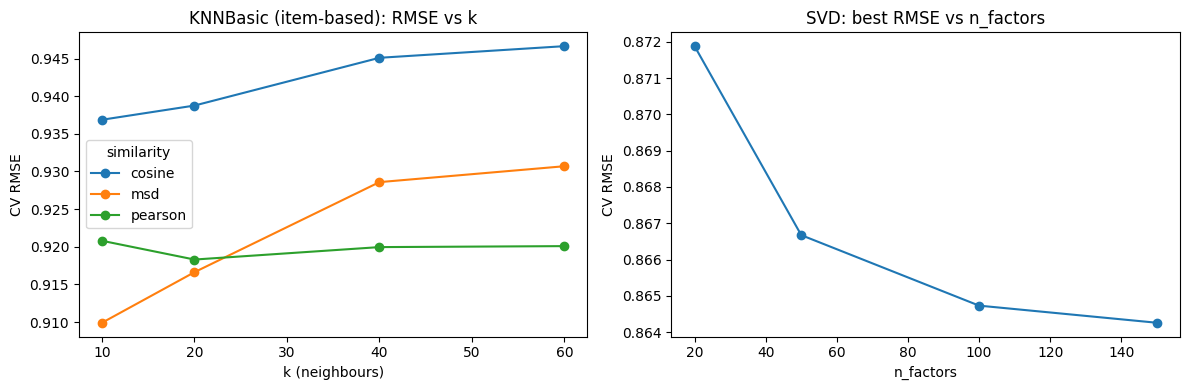

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# KNN: RMSE vs k, one line per similarity measure (best min_k for each point)
knn_plot = knn_res.groupby(["similarity", "param_k"])["mean_test_rmse"].min().unstack(0)
knn_plot.plot(ax=axes[0], marker="o")
axes[0].set(title="KNNBasic (item-based): RMSE vs k", xlabel="k (neighbours)", ylabel="CV RMSE")

# SVD: best RMSE reached for each number of latent factors
svd_plot = svd_res.groupby("param_n_factors")["mean_test_rmse"].min()
svd_plot.plot(ax=axes[1], marker="o")
axes[1].set(title="SVD: best RMSE vs n_factors", xlabel="n_factors", ylabel="CV RMSE")

plt.tight_layout()
plt.show()

In [ ]:
# Final comparison on the 47,546 users NOT used for tuning (same 5 folds for all models)
kf = KFold(n_splits=5, random_state=42, shuffle=True)

models = {
    "KNNBasic default (item-based)": KNNBasic(sim_options={"user_based": False}, verbose=False),
    "KNNBasic tuned":                KNNBasic(**best_knn_params),
    "SVD default":                   SVD(random_state=42),
    "SVD tuned":                     SVD(**best_svd_params),
}

results = {}
for name, model in models.items():
    res = cross_validate(model, eval_data, measures=["RMSE"], cv=kf, verbose=False)
    results[name] = res["test_rmse"]
    print(f"done: {name}")

tuning_summary = pd.DataFrame(results, index=[f"Fold {i}" for i in range(1, 6)])
tuning_summary.loc["Mean"] = tuning_summary.iloc[:5].mean()
tuning_summary.loc["Std"]  = tuning_summary.iloc[:5].std()
display(tuning_summary.round(4))

done: KNNBasic default (item-based)
done: KNNBasic tuned
done: SVD default
done: SVD tuned


,KNNBasic default (item-based),KNNBasic tuned,SVD default,SVD tuned
Fold 1,0.9182,0.8860,0.8644,0.8614
Fold 2,0.9180,0.8846,0.8650,0.8613
Fold 3,0.9174,0.8847,0.8653,0.8609
Fold 4,0.9190,0.8873,0.8660,0.8623
Fold 5,0.9175,0.8845,0.8635,0.8602
Mean,0.9180,0.8854,0.8648,0.8612
Std,0.0007,0.0012,0.0009,0.0007


### Tuning results

Hyperparameters were selected through 3-fold cross-validation using 5,000 users and then evaluated through 5-fold cross-validation on the remaining 47,546 users, who were not included in the tuning process.

- **KNNBasic:** The best-performing configuration used k = 10, min_k = 3, and MSD similarity (item-based). Mean RMSE decreased from 0.9180 to 0.8854, an improvement of 0.033 or approximately 3.6%. The tuned model achieved lower RMSE in all five folds. MSD with fewer neighbours performed best, while RMSE generally increased as k increased. This suggests that including more, potentially less-similar neighbours introduced noise rather than improving predictions. Cosine was the weakest of the similarity measures tested.

- **SVD:** The best-performing configuration used n_factors = 150, n_epochs = 40, lr_all = 0.01, and reg_all = 0.10. Mean RMSE decreased from 0.8648 to 0.8612, an improvement of 0.004 or approximately 0.4%. The tuned model achieved lower RMSE in all five folds. The best-performing configurations generally combined a higher learning rate and more training epochs with stronger regularization. This allowed the model to train longer while controlling the risk of overfitting. The improvement was relatively small, suggesting that the default SVD configuration was already performing well.

- **Model comparison:** SVD achieved lower RMSE than KNNBasic both before tuning (0.8648 versus 0.9180) and after tuning (0.8612 versus 0.8854). It also performed better in every fold. Although tuning benefited KNNBasic more substantially than SVD, narrowing the performance gap, it did not change the overall ranking. The fold-to-fold standard deviations were approximately 0.001, considerably smaller than the differences in mean RMSE between the models.

- **Caveats:** All selected hyperparameter values were at the boundaries of their respective search ranges. For KNNBasic, k = 10 was the smallest value tested, while for SVD, n_factors = 150, n_epochs = 40, lr_all = 0.01, and reg_all = 0.10 were the largest values tested. Exploring wider ranges may therefore yield further improvements. Additionally, KNNBasic was evaluated using item-based similarity only because the user-based version, with approximately 52,000 users, exceeded the available memory in Google Colab.

# Top-N Predictions and Hit Rate

We generated the Top 10 book recommendations for each user using both tuned models and evaluated their performance using Hit Rate@10.

- **Users:** A random sample of 5,000 users who were not included in hyperparameter tuning. Each user had at least four ratings before the hold-out, ensuring that at least three ratings remained available for training (`min_n_ratings=3`).

- **Leave-one-out evaluation:** One rating per user was held out, and both models were trained on the remaining ratings. Each model then ranked the books that the user had not previously rated to generate a Top 10 recommendation list.

- **Hit definition:** A hit was counted when the user's held-out book appeared in their Top 10 recommendations. We calculated Hit Rate@10 using two definitions: one counting all held-out books, and another counting only books the user rated positively (4 or 5).

The complete set of held-out ratings and Top 10 recommendations was saved in `outputs/leftout_ratings.csv` and `outputs/top10_recommendations.csv`, respectively. The notebook includes previews of these files and examples of recommendations for selected users.

In [ ]:
from collections import defaultdict

# accept list of predictions and n of top n
#this is like our scoring algorithm for reco engines

def get_top_n(predictions, n=10):

    # First map the predictions to each user.
    top_n = defaultdict(list)
    for uid, iid, true_r, est, _ in predictions:
        # top_n = is a dictionary to map rating to a userid as key
        # est = predicted rating
        # iid = movie id
        # uid = user id
        top_n[uid].append((iid, est))

    # Then sort the predictions for each user and retrieve the k highest ones.
    for uid, user_ratings in top_n.items():

        # x[1] refers to the est score, which means sort highest to lowest using the rating per user
        user_ratings.sort(key=lambda x: x[1], reverse=True)
        top_n[uid] = user_ratings[:n]

    return top_n


In [ ]:
#to illustrate how to compute for hit rate, we will use the Leave One Out dataset

from surprise.model_selection import LeaveOneOut

# Let's rebuild our models
# A reader is still needed but only the rating_scale param is required.
# this indicates our rating is 1 to 5 only

reader = Reader(rating_scale=(1, 5))

# The columns must correspond to user id, item id and ratings (in that order).
# Hit rate on 5,000 users who were NOT used for tuning
data = hr_data

#Build a "leave one out" train/test split for evaluating top-N recommenders
LOOCV = LeaveOneOut(n_splits=1, random_state=1, min_n_ratings=3)
for train, test in LOOCV.split(data):
    LOOCVTrain = train
    LOOCVTest = test

#Save leave one out test predictions
leftoutpredictions = LOOCVTest

#And build an anti-test-set for building predictions
LOOCVAntiTestSet = LOOCVTrain.build_anti_testset()

# using hypertuned
knn = KNNBasic(**best_knn_params)
svd = SVD(**best_svd_params)

# fit using generated training set from data
knn.fit(LOOCVTrain)
svd.fit(LOOCVTrain)

# generate predictions
knn_predictions = knn.test(LOOCVAntiTestSet)
svd_predictions = svd.test(LOOCVAntiTestSet)

del LOOCVAntiTestSet

In [ ]:
import os

OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Fast book_id -> title lookup (replaces get_title_from_id)
title_lookup = books.set_index("book_id")["title"]

# One held-out rating per user from the Leave-One-Out split
leftout_df = pd.DataFrame(leftoutpredictions, columns=["user_id", "book_id", "rating"])
leftout_df["title"] = leftout_df["book_id"].map(title_lookup)
leftout_df.to_csv(f"{OUTPUT_DIR}/leftout_ratings.csv", index=False)

print(f"Held-out ratings: {len(leftout_df):,} users -> {OUTPUT_DIR}/leftout_ratings.csv")
print("Held-out ratings by star value:")
print(leftout_df["rating"].value_counts().sort_index().to_string())
display(leftout_df.head())

Held-out ratings: 5,000 users -> outputs/leftout_ratings.csv
Held-out ratings by star value:
rating
1.0     128
2.0     264
3.0    1049
4.0    1707
5.0    1852


,user_id,book_id,rating,title
0,1,407,2.0,Bel Canto
1,40,285,3.0,"The Rosie Project (Don Tillman, #1)"
2,65,14,4.0,Animal Farm
3,75,144,5.0,"Unbroken: A World War II Story of Survival, Re..."
4,114,13,3.0,1984


In [ ]:
knn_top_n = get_top_n(knn_predictions, n=10)
svd_top_n = get_top_n(svd_predictions, n=10)

def top_n_to_df(top_n, model_name):
    """One row per (user, recommended book), ranked 1-10."""
    rows = [(uid, model_name, rank, iid, est)
            for uid, recs in top_n.items()
            for rank, (iid, est) in enumerate(recs, start=1)]
    return pd.DataFrame(rows, columns=["user_id", "model", "rank", "book_id", "predicted_rating"])

held_out = dict(zip(leftout_df["user_id"], leftout_df["book_id"]))

recs_df = pd.concat([top_n_to_df(knn_top_n, "KNNBasic"),
                     top_n_to_df(svd_top_n, "SVD")], ignore_index=True)
recs_df["title"] = recs_df["book_id"].map(title_lookup)
recs_df["is_held_out_book"] = recs_df["book_id"] == recs_df["user_id"].map(held_out)

recs_df.to_csv(f"{OUTPUT_DIR}/top10_recommendations.csv", index=False)
# recs_df.to_parquet(f"{OUTPUT_DIR}/top10_recommendations.parquet", index=False)  # smaller file, optional

print(f"Saved {len(recs_df):,} rows ({recs_df['user_id'].nunique():,} users x 10 books x 2 models) "
      f"-> {OUTPUT_DIR}/top10_recommendations.csv")
print("Held-out book found in Top 10 (should match the 'All held-out books' hits below):")
print(recs_df.groupby("model")["is_held_out_book"].sum().to_string())
display(recs_df.head(10).round(3))

Saved 100,000 rows (5,000 users x 10 books x 2 models) -> outputs/top10_recommendations.csv
Held-out book found in Top 10 (should match the 'All held-out books' hits below):
model
KNNBasic    353
SVD         414


,user_id,model,rank,book_id,predicted_rating,title,is_held_out_book
0,1,KNNBasic,1,358,4.222,"Oh, The Places You'll Go!",False
1,1,KNNBasic,2,291,4.110,Cutting for Stone,False
2,1,KNNBasic,3,407,4.005,Bel Canto,True
3,1,KNNBasic,4,189,4.002,"The Lord of the Rings (The Lord of the Rings, ...",False
4,1,KNNBasic,5,157,4.002,Green Eggs and Ham,False
5,1,KNNBasic,6,21,3.972,Harry Potter and the Order of the Phoenix (Har...,False
6,1,KNNBasic,7,18,3.972,Harry Potter and the Prisoner of Azkaban (Harr...,False
7,1,KNNBasic,8,401,3.930,A Farewell to Arms,False
8,1,KNNBasic,9,59,3.924,Charlotte's Web,False
9,1,KNNBasic,10,124,3.920,Room,False


In [ ]:
def show_user(uid):
    """Held-out book plus both models' Top 10 side by side. ✓ marks the held-out book."""
    h = leftout_df.loc[leftout_df["user_id"] == uid].iloc[0]
    print(f"\nUser {uid} | held-out book: {h['title']} (rated {h['rating']:.0f}★)")
    user_recs = recs_df[recs_df["user_id"] == uid].copy()
    user_recs["title"] = user_recs["title"] + user_recs["is_held_out_book"].map({True: "  ✓", False: ""})
    display(user_recs.pivot(index="rank", columns="model", values="title"))

hit_both  = recs_df.groupby("user_id")["is_held_out_book"].sum().loc[lambda s: s == 2].index
svd_only  = recs_df[recs_df["model"] == "SVD"].groupby("user_id")["is_held_out_book"].any()
knn_only  = recs_df[recs_df["model"] == "KNNBasic"].groupby("user_id")["is_held_out_book"].any()
svd_not_knn = svd_only[svd_only & ~knn_only].index

examples = (list(hit_both[:1])                                   # both models found the book
            + list(svd_not_knn[:1])                              # only SVD found it
            + list(leftout_df["user_id"].sample(2, random_state=42)))  # two random users
for uid in examples:
    show_user(uid)


User 615 | held-out book: The Lord of the Rings (The Lord of the Rings, #1-3) (rated 5★)


model,KNNBasic,SVD
rank,,
1,"The Lord of the Rings (The Lord of the Rings, ...","The Lord of the Rings (The Lord of the Rings, ..."
2,The Last Olympian (Percy Jackson and the Olymp...,Cutting for Stone
3,The Hitchhiker's Guide to the Galaxy (Hitchhik...,"The Wise Man's Fear (The Kingkiller Chronicle,..."
4,A Christmas Carol,The Stand
5,"The Magician's Nephew (Chronicles of Narnia, #6)","Unbroken: A World War II Story of Survival, Re..."
6,The Martian,Rebecca
7,The Guernsey Literary and Potato Peel Pie Society,"Winnie-the-Pooh (Winnie-the-Pooh, #1)"
8,The Immortal Life of Henrietta Lacks,The Count of Monte Cristo
9,"The Golden Compass (His Dark Materials, #1)",Where the Sidewalk Ends



User 65 | held-out book: Animal Farm (rated 4★)


model,KNNBasic,SVD
rank,,
1,Bel Canto,"Ender's Game (Ender's Saga, #1)"
2,The Nightingale,The Name of the Wind (The Kingkiller Chronicle...
3,The Stand,The Hitchhiker's Guide to the Galaxy (Hitchhik...
4,"Anne of Green Gables (Anne of Green Gables, #1)",Where the Wild Things Are
5,Bridge to Terabithia,"The Lord of the Rings (The Lord of the Rings, ..."
6,"Ender's Game (Ender's Saga, #1)",The Fellowship of the Ring (The Lord of the Ri...
7,Charlie and the Chocolate Factory (Charlie Buc...,Animal Farm ✓
8,"The Wise Man's Fear (The Kingkiller Chronicle,...","The Wise Man's Fear (The Kingkiller Chronicle,..."
9,To Kill a Mockingbird,Ready Player One



User 13949 | held-out book: City of Ashes (The Mortal Instruments, #2) (rated 5★)


model,KNNBasic,SVD
rank,,
1,The Guernsey Literary and Potato Peel Pie Society,"The Wise Man's Fear (The Kingkiller Chronicle,..."
2,"The Magician's Nephew (Chronicles of Narnia, #6)",The Nightingale
3,"Eat, Pray, Love","Unbroken: A World War II Story of Survival, Re..."
4,"The Da Vinci Code (Robert Langdon, #2)",The Name of the Wind (The Kingkiller Chronicle...
5,"Little Women (Little Women, #1)","Outlander (Outlander, #1)"
6,"Beautiful Creatures (Caster Chronicles, #1)",Harry Potter and the Deathly Hallows (Harry Po...
7,"Bridget Jones's Diary (Bridget Jones, #1)","A Storm of Swords (A Song of Ice and Fire, #3)"
8,"Fifty Shades of Grey (Fifty Shades, #1)",A Light in the Attic
9,White Oleander,The Help



User 31814 | held-out book: Harry Potter and the Prisoner of Azkaban (Harry Potter, #3) (rated 5★)


model,KNNBasic,SVD
rank,,
1,World War Z: An Oral History of the Zombie War,The Name of the Wind (The Kingkiller Chronicle...
2,"Anne of Green Gables (Anne of Green Gables, #1)","The Wise Man's Fear (The Kingkiller Chronicle,..."
3,The Name of the Wind (The Kingkiller Chronicle...,"The Lord of the Rings (The Lord of the Rings, ..."
4,Green Eggs and Ham,"The Return of the King (The Lord of the Rings,..."
5,"The Lord of the Rings (The Lord of the Rings, ...",Where the Sidewalk Ends
6,The Cat in the Hat,"The Two Towers (The Lord of the Rings, #2)"
7,"The Return of the King (The Lord of the Rings,...",The Princess Bride
8,The Diary of a Young Girl,The Ultimate Hitchhiker's Guide to the Galaxy
9,East of Eden,Harry Potter and the Prisoner of Azkaban (Harr...


In [ ]:
# Hit Rate@N, counted per user: a hit only when a user's own held-out book
# appears in that same user's Top-N list. (The template version counted a hit
# if the book appeared in ANY user's list, which overstated the hit rate.)
# min_rating: if set, only held-out books the user rated >= min_rating are
# evaluated, e.g. min_rating=4 measures how often liked books are recovered.

def hitrate(topNPredictions, leftoutpredictions, min_rating=None):
    """Hit Rate@N. If min_rating is set, only held-out books rated >= min_rating count."""
    hits = total = 0
    for uid, iid, true_rating in leftoutpredictions:
        if min_rating is not None and true_rating < min_rating:
            continue
        total += 1
        if iid in [book_id for book_id, _ in topNPredictions.get(uid, [])]:
            hits += 1
    return hits / total, hits, total

In [ ]:
rows = []
for label, thr in [("All held-out books", None), ("Liked books only (rating ≥ 4)", 4)]:
    for model, top_n in [("KNNBasic", knn_top_n), ("SVD", svd_top_n)]:
        hr, h, t = hitrate(top_n, leftoutpredictions, min_rating=thr)
        rows.append({"held-out set": label, "model": model,
                     "hits": h, "users": t, "HitRate@10": round(hr, 4)})
hitrate_table = pd.DataFrame(rows)
display(hitrate_table)

knn_hit_rate = hitrate_table.query("model == 'KNNBasic'")["HitRate@10"].iloc[-1]
svd_hit_rate = hitrate_table.query("model == 'SVD'")["HitRate@10"].iloc[-1]

,held-out set,model,hits,users,HitRate@10
0,All held-out books,KNNBasic,353,5000,0.0706
1,All held-out books,SVD,414,5000,0.0828
2,Liked books only (rating ≥ 4),KNNBasic,298,3559,0.0837
3,Liked books only (rating ≥ 4),SVD,381,3559,0.1071


In [ ]:
# Diversity / popularity concentration of each model's Top-10 lists
n_users_rec = recs_df["user_id"].nunique()
rows = []
for model, g in recs_df.groupby("model"):
    counts = g["title"].value_counts()
    rows.append({"model": model,
                 "distinct books recommended": g["book_id"].nunique(),
                 "catalog coverage": g["book_id"].nunique() / filtered_popular_active_df["book_id"].nunique(),
                 "share of slots: 10 most-recommended books": counts.head(10).sum() / len(g),
                 "books shown to ≥20% of users": int((counts >= 0.2 * n_users_rec).sum())})
display(pd.DataFrame(rows).set_index("model").style.format(
    {"catalog coverage": "{:.0%}", "share of slots: 10 most-recommended books": "{:.0%}"}))

for model, g in recs_df.groupby("model"):
    print(f"\n{model}: most-recommended books (% of users)")
    print((g["title"].value_counts().head(5) / n_users_rec).map("{:.0%}".format).to_string())

knn_sets = recs_df[recs_df["model"] == "KNNBasic"].groupby("user_id")["book_id"].apply(set)
svd_sets = recs_df[recs_df["model"] == "SVD"].groupby("user_id")["book_id"].apply(set)
overlap = knn_sets.combine(svd_sets, lambda a, b: len(a & b))
print(f"\nAverage overlap between a user's KNN and SVD Top 10: {overlap.mean():.1f} books")

,distinct books recommended,catalog coverage,share of slots: 10 most-recommended books,books shown to ≥20% of users
model,,,,
KNNBasic,320,100%,8%,0
SVD,209,65%,54%,14



KNNBasic: most-recommended books (% of users)
title
The Book Thief                                             10%
The Return of the King (The Lord of the Rings, #3)          9%
Harry Potter and the Deathly Hallows (Harry Potter, #7)     8%
The Lord of the Rings (The Lord of the Rings, #1-3)         8%
The Two Towers (The Lord of the Rings, #2)                  8%

SVD: most-recommended books (% of users)
title
The Wise Man's Fear (The Kingkiller Chronicle, #2)                        85%
The Name of the Wind (The Kingkiller Chronicle, #1)                       84%
Unbroken: A World War II Story of Survival, Resilience, and Redemption    58%
Harry Potter and the Goblet of Fire (Harry Potter, #4)                    52%
Harry Potter and the Deathly Hallows (Harry Potter, #7)                   50%

Average overlap between a user's KNN and SVD Top 10: 1.4 books


In [ ]:
# Create a dataframe containing the corrected Hit Rate@10
hitrate_df = pd.DataFrame({
    'knn': [knn_hit_rate],
    'svd': [svd_hit_rate]
}, index=['HitRate@10'])


final_metric_df = tuning_summary[["KNNBasic tuned", "SVD tuned"]].copy()
final_metric_df.columns = ["knn", "svd"]
final_metric_df.loc["HitRate@10 (liked books)"] = [knn_hit_rate, svd_hit_rate]
print("Metric comparison (tuned models)")
display(final_metric_df.round(4))

Metric comparison (tuned models)


,knn,svd
Fold 1,0.8860,0.8614
Fold 2,0.8846,0.8613
Fold 3,0.8847,0.8609
Fold 4,0.8873,0.8623
Fold 5,0.8845,0.8602
Mean,0.8854,0.8612
Std,0.0012,0.0007
HitRate@10 (liked books),0.0837,0.1071


## Making SVD's recommendations more varied

SVD's predicted rating is: global average + user bias + book bias + (user factors · book factors). The book bias is large for books nearly everyone rates highly, and it is added to every user's score, so the same crowd favourites rise to the top of most lists. Only the last term reflects an individual user's taste.

To test this, we re-rank the same SVD predictions while scaling down the book-bias term by α: α = 0 is the original ranking, α = 1 ranks purely on personal taste. For each α we measure Hit Rate@10 (liked books) and recommendation variety.

,HitRate@10 (liked),hits,distinct books,catalog coverage,share of slots: top-10 books,most-shown book (% users)
alpha,,,,,,
0.000000,10.45%,372,208,65%,56%,89%
0.250000,11.21%,399,256,80%,47%,79%
0.500000,13.52%,481,297,93%,33%,60%
0.750000,14.84%,528,316,99%,15%,24%
1.000000,12.95%,461,318,99%,13%,17%


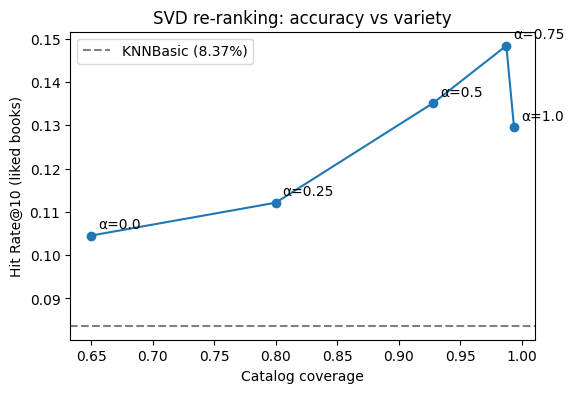

In [ ]:
# Re-rank SVD's predictions with the book bias scaled by (1 - alpha) without retraining the model
trainset = LOOCVTrain
pred_df = pd.DataFrame([(p.uid, p.iid) for p in svd_predictions], columns=["user_id", "book_id"])
u_in = np.array([trainset.to_inner_uid(u) for u in pred_df["user_id"]])
i_in = np.array([trainset.to_inner_iid(i) for i in pred_df["book_id"]])

base     = trainset.global_mean + svd.bu[u_in]                        # same for every book of a user
book_b   = svd.bi[i_in]                                               # popularity / "crowd favourite" term
personal = np.einsum("ij,ij->i", svd.pu[u_in], svd.qi[i_in])          # user taste x book profile

liked = leftout_df[leftout_df["rating"] >= 4][["user_id", "book_id"]]
n_books = filtered_popular_active_df["book_id"].nunique()

rows, rerank_tops = [], {}
for alpha in [0, 0.25, 0.5, 0.75, 1.0]:
    score = base + (1 - alpha) * book_b + personal
    top = (pred_df.assign(score=score)
           .sort_values(["user_id", "score"], ascending=[True, False])
           .groupby("user_id").head(10))
    rerank_tops[alpha] = top
    counts = top["book_id"].value_counts()
    hits = liked.merge(top, on=["user_id", "book_id"]).shape[0]
    rows.append({"alpha": alpha,
                 "HitRate@10 (liked)": hits / len(liked),
                 "hits": hits,
                 "distinct books": top["book_id"].nunique(),
                 "catalog coverage": top["book_id"].nunique() / n_books,
                 "share of slots: top-10 books": counts.head(10).sum() / len(top),
                 "most-shown book (% users)": counts.iloc[0] / top["user_id"].nunique()})

rerank_df = pd.DataFrame(rows).set_index("alpha")
display(rerank_df.style.format({"HitRate@10 (liked)": "{:.2%}", "catalog coverage": "{:.0%}",
                                "share of slots: top-10 books": "{:.0%}",
                                "most-shown book (% users)": "{:.0%}"}))

# Trade-off plot: accuracy vs variety
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(rerank_df["catalog coverage"], rerank_df["HitRate@10 (liked)"], marker="o")
for a, r in rerank_df.iterrows():
    ax.annotate(f"α={a}", (r["catalog coverage"], r["HitRate@10 (liked)"]),
                textcoords="offset points", xytext=(5, 5))
ax.axhline(knn_hit_rate, ls="--", color="grey", label=f"KNNBasic ({knn_hit_rate:.2%})")
ax.set(xlabel="Catalog coverage", ylabel="Hit Rate@10 (liked books)",
       title="SVD re-ranking: accuracy vs variety")
ax.legend()
plt.show()

In [ ]:
# Choose alpha on half A of the users, then test it on half B (users it was not chosen on)
split_rng = np.random.default_rng(7)
users = leftout_df["user_id"].unique()
half_a = set(split_rng.choice(users, size=len(users) // 2, replace=False))

liked_split = liked.assign(half=np.where(liked["user_id"].isin(half_a), "A (choose α)", "B (test)"))

rows = []
for alpha, top in rerank_tops.items():
    m = liked_split.merge(top[["user_id", "book_id"]], on=["user_id", "book_id"],
                          how="left", indicator=True)
    m["hit"] = m["_merge"] == "both"
    for half, g in m.groupby("half"):
        rows.append({"alpha": alpha, "half": half, "HitRate@10": g["hit"].mean(), "users": len(g)})

val = pd.DataFrame(rows).pivot(index="alpha", columns="half", values="HitRate@10")
display(val.style.format("{:.2%}"))

best_alpha = val["A (choose α)"].idxmax()
print(f"Alpha chosen on half A: {best_alpha}")
print(f"Half B (test): α=0 -> {val.loc[0, 'B (test)']:.2%} | α={best_alpha} -> {val.loc[best_alpha, 'B (test)']:.2%}")

half,A (choose α),B (test)
alpha,,
0.000000,10.47%,10.43%
0.250000,10.80%,11.63%
0.500000,13.41%,13.63%
0.750000,14.29%,15.39%
1.000000,12.91%,13.00%


Alpha chosen on half A: 0.75
Half B (test): α=0 -> 10.43% | α=0.75 -> 15.39%


In [ ]:
# Re-ranked SVD Top 10 as a separate output (the original top10_recommendations.csv is unchanged)
reranked = rerank_tops[best_alpha].copy()
reranked["rank"] = reranked.groupby("user_id").cumcount() + 1
reranked["model"] = f"SVD re-ranked (α={best_alpha})"
reranked["title"] = reranked["book_id"].map(title_lookup)
reranked["is_held_out_book"] = reranked["book_id"] == reranked["user_id"].map(held_out)
reranked = reranked.rename(columns={"score": "rerank_score"})[
    ["user_id", "model", "rank", "book_id", "rerank_score", "title", "is_held_out_book"]]

reranked.to_csv(f"{OUTPUT_DIR}/top10_recommendations_svd_reranked.csv", index=False)
print(f"Saved {len(reranked):,} rows -> {OUTPUT_DIR}/top10_recommendations_svd_reranked.csv")
display(reranked.head(10).round(3))

Saved 50,000 rows -> outputs/top10_recommendations_svd_reranked.csv


,user_id,model,rank,book_id,rerank_score,title,is_held_out_book
63,1,SVD re-ranked (α=0.75),1,296,3.739,The Very Hungry Caterpillar Board Book,False
71,1,SVD re-ranked (α=0.75),2,337,3.721,The Ultimate Hitchhiker's Guide to the Galaxy,False
59,1,SVD re-ranked (α=0.75),3,157,3.720,Green Eggs and Ham,False
172,1,SVD re-ranked (α=0.75),4,19,3.719,The Fellowship of the Ring (The Lord of the Ri...,False
105,1,SVD re-ranked (α=0.75),5,65,3.716,Slaughterhouse-Five,False
170,1,SVD re-ranked (α=0.75),6,189,3.710,"The Lord of the Rings (The Lord of the Rings, ...",False
146,1,SVD re-ranked (α=0.75),7,339,3.705,Goodnight Moon,False
37,1,SVD re-ranked (α=0.75),8,155,3.702,"The Two Towers (The Lord of the Rings, #2)",False
24,1,SVD re-ranked (α=0.75),9,407,3.694,Bel Canto,True
34,1,SVD re-ranked (α=0.75),10,161,3.693,"The Return of the King (The Lord of the Rings,...",False


**Validation:** to check that the gain is not just from choosing α on the evaluation users, the 5,000 users were split in half. α was chosen on half A (α = 0.75) and tested on half B, where Hit Rate@10 on liked books rose from 10.43% at α = 0 to 15.39% at α = 0.75. The improvement holds on users the setting was not chosen on. The re-ranked SVD list is saved separately as `top10_recommendations_svd_reranked.csv`.

## SVD Re-ranking Results

Reducing the influence of the book-bias term made SVD's recommendations **more diverse and more effective at recovering books users rated positively**, although the improvement was not consistent across all values of α.

- **Recommendation variety:** At α = 0.75, SVD recommended 316 of the 320 available books, increasing catalog coverage from 65% to 99%. The most frequently recommended book appeared in 24% of users' lists, down from 89%. Similarly, the 10 most-recommended books accounted for only 15% of all Top-10 recommendation slots, compared with 56% in the original model. This indicates a substantial reduction in the concentration of recommendations.

- **Hit Rate@10:** The hit rate for positively rated books increased from 10.45% to 14.84% at α = 0.75, before declining to 12.95% at α = 1, when the book-bias term was completely removed. This suggests that retaining some influence from the book-bias term provides a better balance between recommendation variety and the recovery of books users liked.

- **Interpretation:** The book-bias term captures general tendencies associated with individual books, while the personalized component accounts for differences in users' rating patterns. Reducing the influence of book bias allows the personalized component to have a greater effect on the ranking. This appears to produce recommendations that are less concentrated on the same highly rated titles and more successful at recovering books users rated positively. However, the lower hit rate at α = 1 suggests that removing the book-bias term entirely is not ideal.

- **Caveats:** These results are based on a single leave-one-out evaluation split. The α = 0 result also differs slightly from the main SVD result (10.71%) because the re-ranking procedure uses scores that are not capped at five stars, which can affect the ordering of books with tied or similar scores.

All re-ranked versions achieved a higher Hit Rate@10 than KNNBasic (8.37%). Overall, the results suggest that adjusting SVD's ranking scores is a simple, no-retraining approach to reducing repetitive recommendations while also improving the observed hit rate.

## Answers to Objectives / Questions

**1. How well do KNNBasic and SVD predict users' book ratings, and which model performs more consistently?**

SVD achieved better rating-prediction accuracy than KNNBasic. On the 47,546 users not used for tuning, tuned SVD obtained a mean RMSE of 0.8612, compared with 0.8854 for tuned item-based KNNBasic. Since RMSE is measured on the original 1–5 rating scale, this indicates that SVD produced smaller prediction errors. SVD also achieved lower RMSE in all five folds, both before and after tuning. Both models showed stable performance across folds, with standard deviations of approximately 0.001, suggesting that the results were consistent across the different folds. Tuning improved both models, although the improvement was considerably larger for KNNBasic (3.6% reduction in RMSE) than for SVD (0.4%). This suggests that the default SVD configuration was already performing well.

**2. How effective are KNNBasic and SVD at generating relevant Top-N book recommendations?**

Hit Rate@10 was evaluated using a leave-one-out split involving 5,000 users who were not included in hyperparameter tuning. Both tuned models were evaluated using the same held-out ratings. When a hit was defined as successfully recommending a book rated 4–5 by the user (3,559 users), SVD achieved a Hit Rate@10 of 10.71% (381 hits), compared with 8.37% for KNNBasic (298 hits). When all held-out books were counted, the rates were 8.28% (414 hits) for SVD and 7.06% (353 hits) for KNNBasic. SVD performed better under both definitions.

Both models recovered positively rated books more often than books rated 1–3. For KNNBasic, the respective hit rates were 8.37% and 3.82%, while SVD achieved 10.71% and 2.29%. This suggests that both models were more successful at recovering books users rated positively than those they rated poorly, making the 4–5 definition more relevant for evaluating recommendations intended to reflect user preferences. For comparison, randomly selecting 10 books from each user's approximately 280 unrated books would result in an expected hit rate of about 3.5%, indicating that both models performed better than this simple random-selection baseline.

One caveat is that these results are based on a single leave-one-out split. Therefore, the observed difference between the models may vary with a different evaluation split.

**3. What patterns or biases are evident in the recommendations produced by the two models?**

- **SVD concentrates recommendations on a relatively small group of books.** It recommended 209 of the 320 available books, with its 10 most-recommended titles accounting for 54% of all Top-10 recommendation slots. *The Wise Man's Fear* and *The Name of the Wind* each appeared in approximately 85% of users' lists. In contrast, KNNBasic recommended all 320 books, and no single title appeared in more than 10% of users' lists. The two models shared an average of only 1.4 books per user's Top 10, indicating substantial differences in their recommendations.

- **Re-ranking can improve recommendation variety and hit rate simultaneously.** Much of SVD's repetition appears to be associated with its book-bias term, which gives highly rated books an advantage across users. Reducing the influence of this term (α = 0.75) increased catalog coverage from 65% to 99% and reduced the most frequently recommended book's share from 89% to 24% of users' lists (shares from the re-ranking table, where scores are not capped at 5 stars). Hit Rate@10 for positively rated books also increased from 10.43% to 15.39% when evaluated on users not used to select α. These results suggest that reducing the influence of general book popularity can produce more varied recommendations while improving the recovery of books users rated positively.

- **Popularity bias is also introduced by the dataset filtering process.** Only books with at least 3,000 ratings were retained, reducing the original collection of 10,000 books to 320. Consequently, less popular titles were excluded before model training and could not appear in either model's recommendations.

- **Series and co-reading patterns are evident in the cosine item-similarity recommendations.** The cosine nearest-neighbours model (separate from KNNBasic) frequently recommends books from the same series, such as *Twilight* followed by *New Moon*, *Eclipse*, and *Breaking Dawn*. It also recommends bestsellers that tend to be read by similar groups of users. However, because missing ratings were filled with zero and all actual ratings are positive, the resulting similarities primarily reflect shared reading patterns rather than whether users necessarily liked both books.

# Does better RMSE mean a better hit rate?

Not necessarily. RMSE measures how close predicted ratings are to actual ratings, while hit rate measures how often a held-out book appears in a user's Top 10 recommendations.

In our main comparison, the two measures agreed: tuned SVD achieved both a lower RMSE and a higher hit rate than tuned KNNBasic. However, the re-ranking experiment shows that they do not always move together, even within the same model. By reducing the influence of book bias, re-ranked SVD became less accurate at predicting actual ratings, but it recovered liked books more often and produced more varied recommendations.

This shows that the model with the best rating accuracy is not necessarily the best at ranking recommendations. A recommender should therefore be evaluated not only on RMSE, but also on how well it ranks relevant books and how much variety it offers.

In [ ]:
from google.colab import files
files.download(f"{OUTPUT_DIR}/leftout_ratings.csv")
files.download(f"{OUTPUT_DIR}/top10_recommendations.csv")
files.download(f"{OUTPUT_DIR}/top10_recommendations_svd_reranked.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Additional References
- https://en.wikipedia.org/wiki/Collaborative_filtering
- http://recommender-systems.org/collaborative-filtering/
- https://www.geeksforgeeks.org/fuzzywuzzy-python-library/
- https://medium.com/@rishabhbhatia315/recommendation-system-evaluation-metrics-3f6739288870
- http://surpriselib.com/

## Data sets to try
- https://data.world/socialmediadata/beeradvocate
- http://eigentaste.berkeley.edu/dataset/
- https://cseweb.ucsd.edu/~jmcauley/datasets.html